# Solutions to the exercises of Chapter 1

Sample solutions for [Chapter 1, Heat balances and the three modes of heat transfer](../../notebooks/part1_conduction/01_heat_balances.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import numerics, properties
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import numerics, properties
from engtransport.constants import SIGMA_SB
from engtransport.plotting import use_style

use_style()

# the pipe of Chapter 1 (SI units, temperatures in K)
r_i, r_1 = 0.05355, 0.05715
t_ins, k_ins, eps, h = 0.050, 0.045, 0.9, 25.0
T_w, T_inf, T_f = 273.15 + 110.0, 273.15 - 35.0, 273.15


def surface_temperature(t=t_ins, k=k_ins, eps=eps, h=h, T_w=T_w, T_sur=T_inf):
    """Solve the surface balance (1.6), with separate air and surroundings temperatures."""
    R = math.log((r_1 + t) / r_1) / (2 * math.pi * k)
    P = 2 * math.pi * (r_1 + t)
    f = lambda Ts: (T_w - Ts) / R - P * (h * (Ts - T_inf) + eps * SIGMA_SB * (Ts**4 - T_sur**4))
    df = lambda Ts: -1 / R - P * (h + 4 * eps * SIGMA_SB * Ts**3)
    Ts, _ = numerics.newton(f, df, x0=T_w)
    return Ts, (T_w - Ts) / R

## Exercise 1. A clear night

With the sky at $T_{\rm sur} = T_\infty - 20$ K, the surface balance (1.6) keeps its form,
with $T_{\rm sur}$ in the radiation term and $T_\infty$ in the convection term. It is still
monotonic in $T_s$, so Newton's method from $T_s = T_w$ still converges.

In [2]:
for e in (0.9, 0.1):
    Ts0, q0 = surface_temperature(eps=e)
    Ts1, q1 = surface_temperature(eps=e, T_sur=T_inf - 20.0)
    print(f"eps = {e}:  air surroundings T_s = {Ts0 - 273.15:7.2f} C, q' = {q0:.2f} W/m;"
          f"  clear sky T_s = {Ts1 - 273.15:7.2f} C, q' = {q1:.2f} W/m ({100 * (q1 / q0 - 1):+.2f} %)")

eps = 0.9:  air surroundings T_s =  -31.60 C, q' = 63.70 W/m;  clear sky T_s =  -33.30 C, q' = 64.46 W/m (+1.20 %)
eps = 0.1:  air surroundings T_s =  -31.27 C, q' = 63.55 W/m;  clear sky T_s =  -31.48 C, q' = 63.64 W/m (+0.15 %)


The cold sky lowers the surface temperature of the painted cladding by 1.7 K and raises
the heat loss by 1.2 %. The insulation still carries
almost all of the resistance. The bright cladding hardly feels the sky at all.

The cladding of the pipe stays warmer than the air because heat keeps arriving from the
water. A surface with no heat supply behaves differently. The roof of a parked car loses
heat to the sky by radiation and gains it from the air by convection, so in a steady
state $h(T_\infty - T_s) = \varepsilon\sigma(T_s^4 - T_{\rm sur}^4)$, and $T_s$ must lie
between the sky and the air temperatures. In still air ($h \approx 5$ W/(m² K)) the roof
can be several kelvin colder than the air, so frost forms on it when the air is above
0 °C:

In [3]:
for T_air_C in (2.0, 4.0):
    T_air = 273.15 + T_air_C
    g = lambda Ts: 5.0 * (T_air - Ts) - 0.9 * SIGMA_SB * (Ts**4 - (T_air - 20.0) ** 4)
    Ts, _ = numerics.bisect(g, T_air - 20.0, T_air)
    print(f"air {T_air_C:+.0f} C, sky {T_air_C - 20:+.0f} C, still air: roof at {Ts - 273.15:+.1f} C")

air +2 C, sky -18 C, still air: roof at -6.4 C
air +4 C, sky -16 C, still air: roof at -4.5 C


## Exercise 2. The resistances that were neglected

Per metre of pipe, the water film has $R'_i = 1/(2\pi r_i h_i)$ and the steel wall
$R'_{\rm steel} = \ln(r_1/r_i)/(2\pi k_{\rm steel})$.

In [4]:
R_i = 1 / (2 * math.pi * r_i * 2000.0)
R_steel = math.log(r_1 / r_i) / (2 * math.pi * 50.0)
R_ins = math.log((r_1 + t_ins) / r_1) / (2 * math.pi * k_ins)
print(f"R'_i = {R_i:.2e}, R'_steel = {R_steel:.2e}, R'_ins = {R_ins:.3f} m K/W")
print(f"R'_ins is {R_ins / R_i:.0f} times R'_i and {R_ins / R_steel:.0f} times R'_steel")

A_w, A_steel = math.pi * r_i**2, math.pi * (r_1**2 - r_i**2)
w = properties.water_properties(273.15 + 55.0)
C = w["rho"] * w["cp"] * A_w + 7850.0 * 460.0 * A_steel


def freeze_time(t=t_ins, k=k_ins):
    """Time for the water to reach 0 C, Eq. (1.11)."""
    Ts, _ = surface_temperature(t=t, k=k)
    r_2 = r_1 + t
    hr = eps * SIGMA_SB * (Ts + T_inf) * (Ts**2 + T_inf**2)
    R_tot = math.log(r_2 / r_1) / (2 * math.pi * k) + 1 / (2 * math.pi * r_2 * (h + hr))
    return C * R_tot * math.log((T_w - T_inf) / (T_f - T_inf))


for k in (k_ins, 0.4):
    _, q = surface_temperature(k=k)
    print(f"k_ins = {k}: q' = {q:6.1f} W/m, water reaches 0 C after {freeze_time(k=k) / 3600:5.1f} h")

R'_i = 1.49e-03, R'_steel = 2.07e-04, R'_ins = 2.223 m K/W
R'_ins is 1496 times R'_i and 10734 times R'_steel
k_ins = 0.045: q' =   63.7 W/m, water reaches 0 C after  37.4 h
k_ins = 0.4: q' =  479.0 W/m, water reaches 0 C after   5.0 h


The water film and the steel wall add 1/1500 and 1/10 700 of the insulation's
resistance: neglecting them is right. Soaked insulation is a different matter. With
$k = 0.4$ W/(m K) the heat loss rises 7.5-fold, to 479 W/m, and the water reaches 0 °C
in 5 hours instead of 37. The outer resistance then carries nearly a fifth of the total, so the wind and the emissivity begin to matter again.

## Exercise 3. Designing for an outage

The time $t_f(\delta)$ grows steadily with the insulation thickness $\delta$, so the
thickness that gives $t_f = 48$ h is the root of $t_f(\delta) - 48\ \mathrm{h}$, found by
bisection between 50 mm (37 h) and 150 mm.

thinnest insulation for 48 h: 71.7 mm
  60 mm: t_f =  42.6 h,  q' =  56.0 W/m,  saves   184 kWh per km per day compared with 50 mm
  80 mm: t_f =  51.6 h,  q' =  46.2 W/m,  saves   420 kWh per km per day compared with 50 mm
 100 mm: t_f =  59.4 h,  q' =  40.1 W/m,  saves   566 kWh per km per day compared with 50 mm


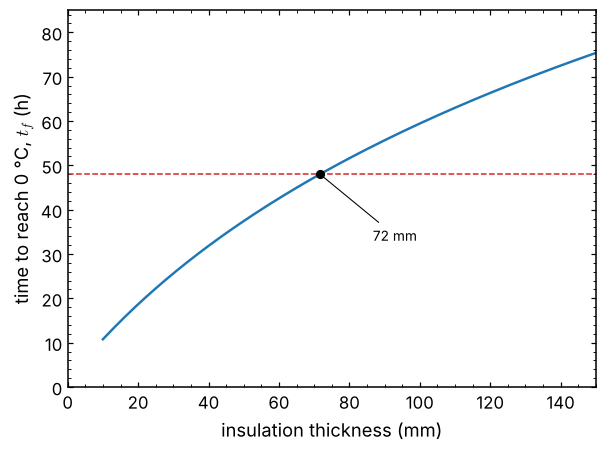

In [5]:
target = 48 * 3600.0
delta, _ = numerics.bisect(lambda d: freeze_time(t=d) - target, 0.050, 0.150, xtol=1e-6)
print(f"thinnest insulation for 48 h: {1e3 * delta:.1f} mm")
_, q50 = surface_temperature(t=0.050)
for d in (0.060, 0.080, 0.100):
    _, qd = surface_temperature(t=d)
    saved = (q50 - qd) * 1000 * 24 / 1000          # kWh per km and per day
    print(f"{1e3 * d:4.0f} mm: t_f = {freeze_time(t=d) / 3600:5.1f} h,  q' = {qd:5.1f} W/m,"
          f"  saves {saved:5.0f} kWh per km per day compared with 50 mm")

thick = np.linspace(0.010, 0.150, 141)
fig, ax = plt.subplots(figsize=(5.4, 4.0))
ax.plot(thick * 1e3, [freeze_time(t=d) / 3600 for d in thick], "C0")
ax.axhline(48, color="C3", ls="--", lw=1)
ax.plot(delta * 1e3, 48, "ko", ms=5)
ax.annotate(f"{1e3 * delta:.0f} mm", (delta * 1e3, 48), (delta * 1e3 + 15, 33), fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7))
ax.set_xlabel("insulation thickness (mm)")
ax.set_ylabel(r"time to reach 0 °C, $t_f$ (h)")
ax.set_xlim(0, 150)
ax.set_ylim(0, 85)
plt.show()

**Figure S1.1.** Time for the water to reach 0 °C after the circulation stops, against
the thickness of insulation, from Eq. (1.11). The dashed line is the 48-hour target.

The target needs about 72 mm, so the standard 80 mm is the choice; it gives 52 hours.
It also saves about 420 kWh of heat per kilometre every day in normal operation compared
with 50 mm, a quantity that matters over a heating season of more than 200 days.

## Exercise 4. Freezing

At 0 °C the water has the density of $\rho \approx 1000$ kg/m³, so a metre of pipe holds
$m = \rho\pi r_i^2 \approx 9.0$ kg. Freezing a quarter of it releases $\tfrac14 mL$, while
the pipe loses heat at the steady rate for $T_w = 0$ °C, $q'_0 = (T_f - T_\infty)/R'_{\rm tot}$.
The time is $t = \tfrac14 mL/q'_0$.

In [6]:
w0 = properties.water_properties(273.16)
m = w0["rho"] * A_w
L_fusion = 334e3
Ts0, q0 = surface_temperature(T_w=T_f)
t_quarter = 0.25 * m * L_fusion / q0
print(f"m = {m:.2f} kg/m, q'(0 C) = {q0:.2f} W/m, a quarter frozen after {t_quarter / 3600:.1f} h")

# the ice layer: a quarter of the cross-section frozen on the wall
r_ice = r_i * math.sqrt(0.75)
R_ice = math.log(r_i / r_ice) / (2 * math.pi * 2.2)
R_tot0 = (T_f - Ts0) / q0 + 1 / (2 * math.pi * (r_1 + t_ins) * (h + eps * SIGMA_SB * (Ts0 + T_inf) * (Ts0**2 + T_inf**2)))
print(f"ice layer: R'_ice = {R_ice:.4f} m K/W, {100 * R_ice / R_tot0:.1f} % of the total resistance")

m = 9.01 kg/m, q'(0 C) = 15.37 W/m, a quarter frozen after 13.6 h
ice layer: R'_ice = 0.0104 m K/W, 0.5 % of the total resistance


Freezing a quarter of the water takes another 14 hours after the 37 needed to cool it
to 0 °C. The heat loss at 0 °C is only 15 W/m, because the driving temperature
difference has fallen from 145 K to 35 K, while the latent heat of a quarter of the
water is as large as the heat given up in cooling it from 20 °C to 0 °C. The ice layer
adds about 0.5 % to the resistance, so it can be neglected. In practice a pipe is at
risk well before a quarter of the water has frozen: ice forms first at the bottom and
at valves and supports, and a plug of ice can block the line or burst it.